In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from scipy.stats import wasserstein_distance
import ot
import itertools

# Safe import for UMAP
try:
    from umap import UMAP
except ImportError:
    raise ImportError(
        "UMAP is missing! Please run 'pip install umap-learn' in your terminal before running this script."
    )

# 1. Setup paths and domain IDs
data_dir = "C:/Users/leona/PythonScripts/MasterThesis/Tierdaten/"
target_id = 1
other_ids = [3, 4, 8, 10]
all_ids = [target_id] + other_ids


# Helper to load data safely
def load_animal_data(animal_id):
    x_path = os.path.join(data_dir, f"X_anim{animal_id}.csv")
    y_path = os.path.join(data_dir, f"Y_anim{animal_id}.csv")

    # Adjust header=None if your CSVs do not have column names
    X = pd.read_csv(x_path, header=None)
    Y = pd.read_csv(y_path, header=None)

    Y.columns = ['target']
    return X, Y


# Load all datasets
data = {}
for aid in all_ids:
    try:
        X, Y = load_animal_data(aid)
        data[aid] = (X, Y)
        print(f"Loaded Animal {aid}: X shape {X.shape}, Y shape {Y.shape}")
    except FileNotFoundError as e:
        print(f"Error loading Animal {aid}: {e}")


Loaded Animal 1: X shape (1853, 14), Y shape (1853, 1)
Loaded Animal 3: X shape (1562, 14), Y shape (1562, 1)
Loaded Animal 4: X shape (2381, 14), Y shape (2381, 1)
Loaded Animal 8: X shape (1777, 14), Y shape (1777, 1)
Loaded Animal 10: X shape (1508, 14), Y shape (1508, 1)


In [2]:

# =====================================================================
# PART 1: STATISTICAL SUMMARIES (From Previous Script)
# =====================================================================

print("\n" + "=" * 50)
print(" 1. TARGET (Y) DISTRIBUTION COMPARISON")
print("=" * 50)

y_stats = []
for aid in all_ids:
    if aid in data:
        y = data[aid][1]['target']
        y_stats.append({
            'Animal': f"anim{aid}",
            'Count': len(y),
            'Mean': y.mean(),
            'Std': y.std(),
            'Min': y.min(),
            'Max': y.max(),
            'Skew': y.skew()
        })
df_y_stats = pd.DataFrame(y_stats)
print(df_y_stats.to_string(index=False))

print("\n" + "=" * 50)
print(" 2. COVARIATE SHIFT: FEATURE MEANS COMPARISON")
print("=" * 50)

X_1, _ = data[target_id]
X_others = pd.concat([data[aid][0] for aid in other_ids], axis=0)

feature_comparison = pd.DataFrame({
    'Feature_Idx': X_1.columns,
    'Anim1_Mean': X_1.mean(),
    'Anim1_Std': X_1.std(),
    'Others_Mean': X_others.mean(),
    'Others_Std': X_others.std()
})

pooled_std = np.sqrt((feature_comparison['Anim1_Std'] ** 2 + feature_comparison['Others_Std'] ** 2) / 2)
feature_comparison['Std_Difference'] = (feature_comparison['Anim1_Mean'] - feature_comparison['Others_Mean']) / (
            pooled_std + 1e-8)
feature_comparison['Abs_Std_Diff'] = feature_comparison['Std_Difference'].abs()
feature_comparison = feature_comparison.sort_values(by='Abs_Std_Diff', ascending=False).drop(columns=['Abs_Std_Diff'])

print(feature_comparison.to_string(index=False))

print("\n" + "=" * 50)
print(" 3. CONCEPT SHIFT: FEATURE-TARGET CORRELATION")
print("=" * 50)

corrs = {}
for aid in all_ids:
    X, Y = data[aid]
    corrs[f"anim{aid}_corr"] = X.corrwith(Y['target'])

df_corrs = pd.DataFrame(corrs)
df_corrs['Others_Avg_Corr'] = df_corrs[[f"anim{aid}_corr" for aid in other_ids]].mean(axis=1)
df_corrs['Corr_Delta'] = df_corrs[f"anim{target_id}_corr"] - df_corrs['Others_Avg_Corr']
df_corrs['Abs_Corr_Delta'] = df_corrs['Corr_Delta'].abs()
df_corrs = df_corrs.sort_values(by='Abs_Corr_Delta', ascending=False).drop(columns=['Abs_Corr_Delta'])

print(df_corrs[[f"anim{target_id}_corr", "Others_Avg_Corr", "Corr_Delta"]])



 1. TARGET (Y) DISTRIBUTION COMPARISON
Animal  Count       Mean        Std       Min        Max      Skew
 anim1   1853 295.965603  90.825027 -7.509853 442.497214 -1.163379
 anim3   1562 252.139454  76.069136 -7.899571 436.195283  0.074017
 anim4   2381 343.033782 125.294050 61.456999 622.322611 -0.343754
 anim8   1777 356.618565  89.453166 77.638505 532.607969  0.016477
anim10   1508 205.135209 116.782624 19.247387 512.888263  0.889714

 2. COVARIATE SHIFT: FEATURE MEANS COMPARISON
 Feature_Idx  Anim1_Mean  Anim1_Std  Others_Mean  Others_Std  Std_Difference
           5    1.806924   1.590185    -0.308779    0.342648        1.839362
           6    2.034131   1.666326    -0.036167    0.637363        1.641112
           3    1.371415   1.205906    -0.103960    0.642341        1.527099
           4    1.734871   2.523439    -0.113604    0.273941        1.029892
           2    1.659580   2.599245    -0.192515    0.375540        0.997343
          13   -1.828748   2.717929     0.066549 


 4. RUNNING DIMENSIONALITY REDUCTION
Computing t-SNE embedding...
Computing UMAP embedding...


C:\Users\leona\PythonScripts\MasterThesis\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


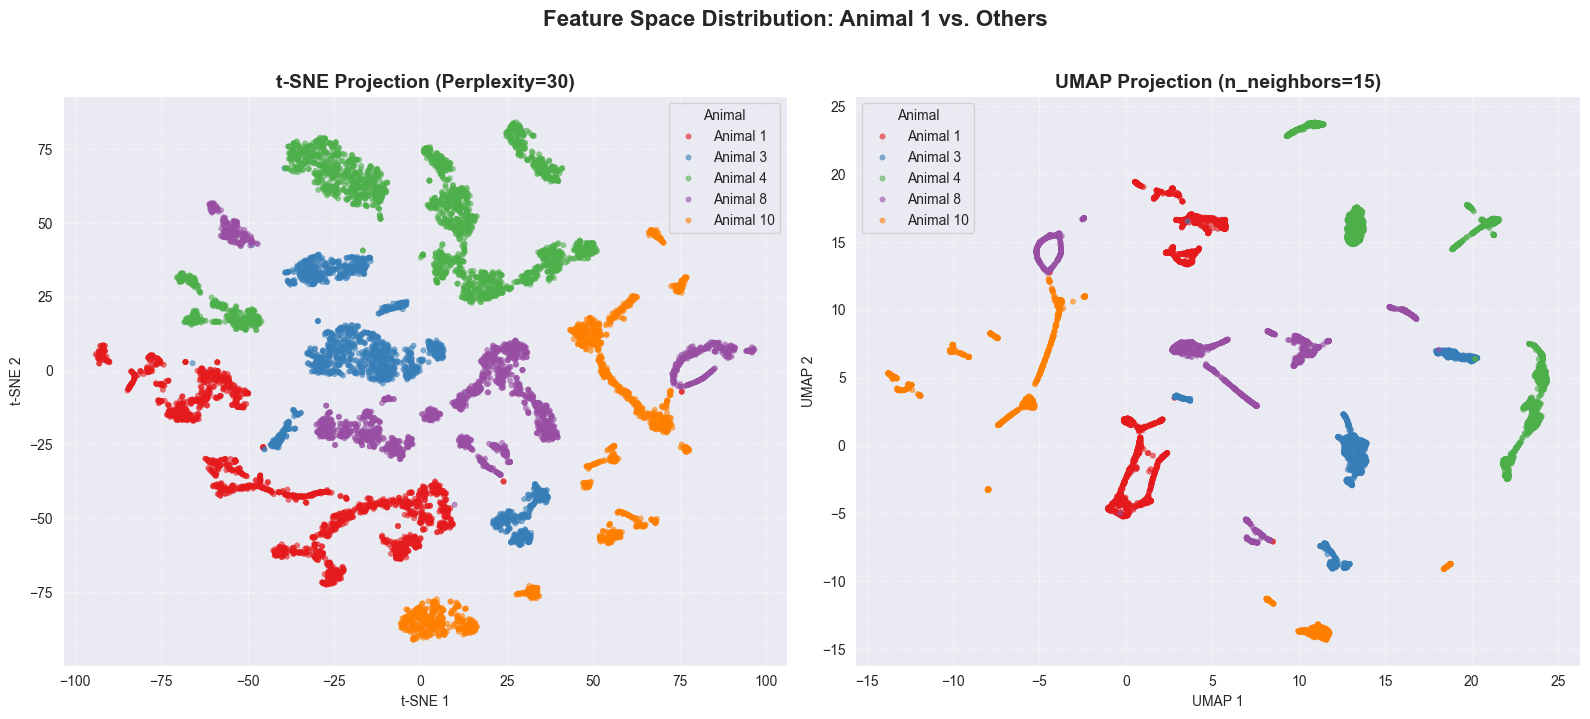


Process finished! Projections plotted successfully.


In [3]:

# =====================================================================
# PART 2: DIMENSIONALITY REDUCTION & PLOTTING (New Extension)
# =====================================================================

print("\n" + "=" * 50)
print(" 4. RUNNING DIMENSIONALITY REDUCTION")
print("=" * 50)

# 1. Combine all features and track where they came from
combined_features = []
domain_labels = []

for aid in all_ids:
    if aid in data:
        X_array = data[aid][0].values
        combined_features.append(X_array)
        domain_labels.extend([f"Animal {aid}"] * len(X_array))

X_combined = np.vstack(combined_features)
y_labels = np.array(domain_labels)

# 2. Standardize features (highly recommended before distance-based projections)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

# 3. Fit t-SNE
print("Computing t-SNE embedding...")
tsne = TSNE(n_components=2, perplexity=30, random_state=100, n_jobs=-1)
X_tsne = tsne.fit_transform(X_scaled)

# 4. Fit UMAP
print("Computing UMAP embedding...")
umap_model = UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=100, n_jobs=-1)
X_umap = umap_model.fit_transform(X_scaled)

# 5. Build clean Plotting DataFrame
df_projections = pd.DataFrame({
    't-SNE 1': X_tsne[:, 0],
    't-SNE 2': X_tsne[:, 1],
    'UMAP 1': X_umap[:, 0],
    'UMAP 2': X_umap[:, 1],
    'Animal': y_labels
})

# 6. Generate the side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Pick a clean, high-contrast palette.
# We use a custom order so Animal 1 stands out clearly from the others.
unique_animals = [f"Animal {aid}" for aid in all_ids]
colors = sns.color_palette("Set1", len(unique_animals))
palette_dict = dict(zip(unique_animals, colors))

# Plot t-SNE
sns.scatterplot(
    x='t-SNE 1', y='t-SNE 2', hue='Animal', hue_order=unique_animals,
    data=df_projections, ax=axes[0], palette=palette_dict, alpha=0.6, edgecolor=None, s=15
)
axes[0].set_title("t-SNE Projection (Perplexity=30)", fontsize=14, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot UMAP
sns.scatterplot(
    x='UMAP 1', y='UMAP 2', hue='Animal', hue_order=unique_animals,
    data=df_projections, ax=axes[1], palette=palette_dict, alpha=0.6, edgecolor=None, s=15
)
axes[1].set_title("UMAP Projection (n_neighbors=15)", fontsize=14, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Feature Space Distribution: Animal 1 vs. Others", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nProcess finished! Projections plotted successfully.")



 5. ALL-PAIRS WASSERSTEIN DISTANCE ANALYSIS
Computing pairwise Wasserstein distances across all animal pairs...

--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---
          Anim 1    Anim 3    Anim 4    Anim 8   Anim 10
Anim 1    0.0000   50.3209   54.5972   60.6530   98.2399
Anim 3   50.3209    0.0000   94.5224  104.4791   66.5366
Anim 4   54.5972   94.5224    0.0000   31.1061  137.8986
Anim 8   60.6530  104.4791   31.1061    0.0000  151.4834
Anim 10  98.2399   66.5366  137.8986  151.4834    0.0000

--- B. Full Feature Space Pairwise Multivariate Wasserstein Distance Matrix ---
         Anim 1  Anim 3  Anim 4  Anim 8  Anim 10
Anim 1   0.0000  6.4784  6.6885  6.5665   7.5787
Anim 3   6.4784  0.0000  2.6583  2.1331   3.3655
Anim 4   6.6885  2.6583  0.0000  2.9221   4.7671
Anim 8   6.5665  2.1331  2.9221  0.0000   2.6396
Anim 10  7.5787  3.3655  4.7671  2.6396   0.0000


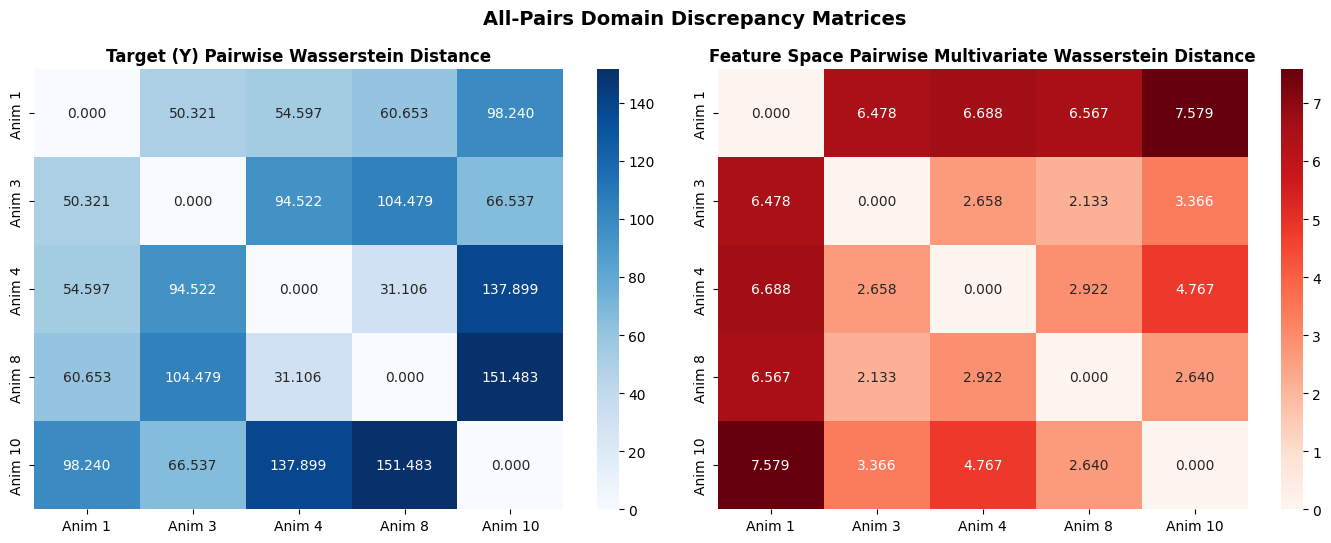

In [9]:


print("\n" + "=" * 50)
print(" 5. ALL-PAIRS WASSERSTEIN DISTANCE ANALYSIS")
print("=" * 50)

# 1. Fit scaler on all data combined to ensure a uniform feature metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Store scaled features and target values per animal
scaled_X = {aid: scaler.transform(data[aid][0]) for aid in all_ids}
targets = {aid: data[aid][1]['target'].values for aid in all_ids}

animal_labels = [f"Anim {aid}" for aid in all_ids]
n_animals = len(all_ids)

# 3. Initialize distance matrices
y_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)
multi_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)

print("Computing pairwise Wasserstein distances across all animal pairs...")

# 4. Compute pairwise distances
for i, id1 in enumerate(all_ids):
    for j, id2 in enumerate(all_ids):
        if i < j:
            # --- A. 1D Target (Y) Wasserstein Distance ---
            w_y = wasserstein_distance(targets[id1], targets[id2])
            y_w_matrix.iloc[i, j] = w_y
            y_w_matrix.iloc[j, i] = w_y  # Symmetric matrix

            # --- B. Multivariate Feature Space Wasserstein Distance ---
            X1 = scaled_X[id1]
            X2 = scaled_X[id2]

            # Cost Matrix: Squared Euclidean distances between all sample pairs
            M = ot.dist(X1, X2, metric='sqeuclidean')
            a = ot.unif(len(X1))
            b = ot.unif(len(X2))

            # Compute exact 2-Wasserstein distance
            w2_dist = np.sqrt(ot.emd2(a, b, M))

            multi_w_matrix.iloc[i, j] = w2_dist
            multi_w_matrix.iloc[j, i] = w2_dist

# 5. Print Tabular Results
print("\n--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---")
print(y_w_matrix.round(4))

print("\n--- B. Full Feature Space Pairwise Multivariate Wasserstein Distance Matrix ---")
print(multi_w_matrix.round(4))

# 6. Plot Pairwise Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(y_w_matrix, annot=True, fmt=".3f", cmap="Blues", cbar=True, ax=axes[0])
axes[0].set_title("Target (Y) Pairwise Wasserstein Distance", fontsize=12, fontweight='bold')

sns.heatmap(multi_w_matrix, annot=True, fmt=".3f", cmap="Reds", cbar=True, ax=axes[1])
axes[1].set_title("Feature Space Pairwise Multivariate Wasserstein Distance", fontsize=12, fontweight='bold')

plt.suptitle("All-Pairs Domain Discrepancy Matrices", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()




 FEATURE-WISE 1D WASSERSTEIN DISTANCE HEATMAP


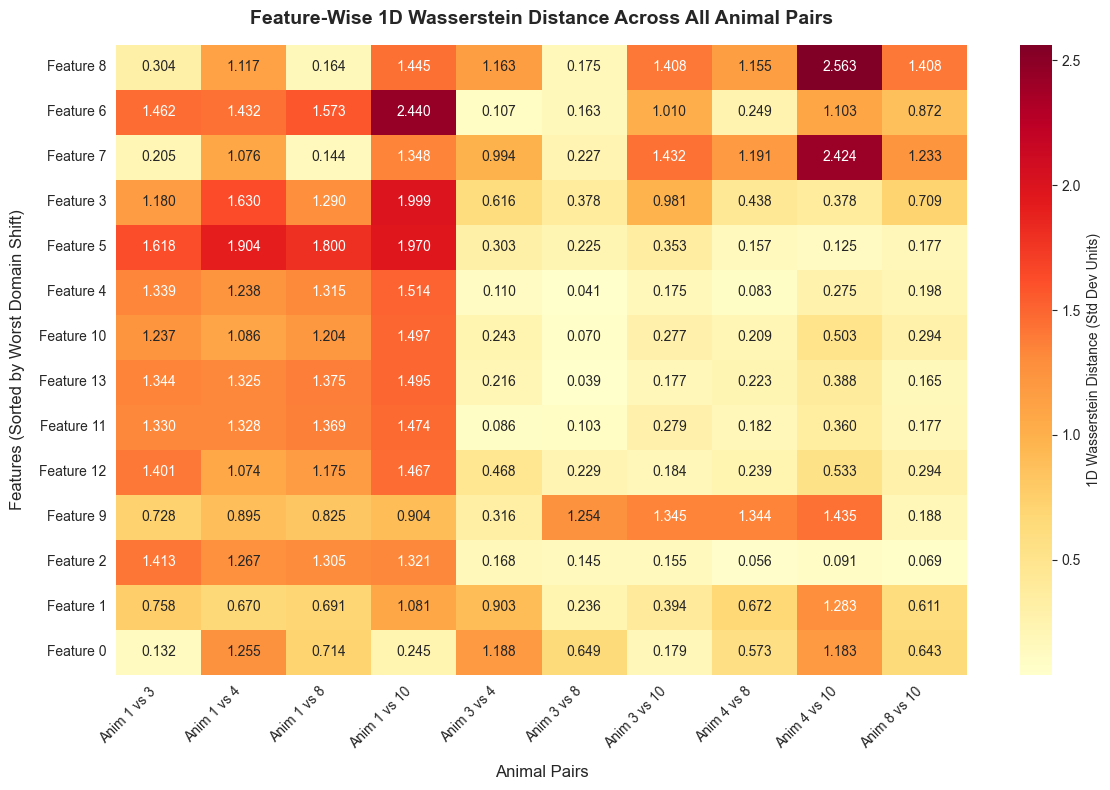

In [5]:
print("\n" + "="*50)
print(" FEATURE-WISE 1D WASSERSTEIN DISTANCE HEATMAP")
print("="*50)

# 1. Fit scaler on all feature data combined for a uniform metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Scale features per animal while keeping feature column names
scaled_data = {}
for aid in all_ids:
    X_scaled_arr = scaler.transform(data[aid][0])
    scaled_data[aid] = pd.DataFrame(X_scaled_arr, columns=data[aid][0].columns)

# Get feature names (or indices)
sample_cols = data[all_ids[0]][0].columns
feature_names = [f"Feature {col}" if isinstance(col, int) else str(col) for col in sample_cols]

# 3. Generate all unique animal pairs (10 pairs for 5 animals)
animal_pairs = list(itertools.combinations(all_ids, 2))
pair_labels = [f"Anim {a1} vs {a2}" for a1, a2 in animal_pairs]

# Initialize matrix: Rows = Features, Columns = Animal Pairs
feature_w_matrix = pd.DataFrame(0.0, index=feature_names, columns=pair_labels)

# 4. Compute 1D Wasserstein distance per feature per animal pair
for (a1, a2), pair_label in zip(animal_pairs, pair_labels):
    df1 = scaled_data[a1]
    df2 = scaled_data[a2]
    
    for orig_col, feat_label in zip(sample_cols, feature_names):
        wd = wasserstein_distance(df1[orig_col], df2[orig_col])
        feature_w_matrix.loc[feat_label, pair_label] = wd

# Sort features by maximum shift observed across any pair (worst offenders at the top)
feature_w_matrix['max_shift'] = feature_w_matrix.max(axis=1)
feature_w_matrix = feature_w_matrix.sort_values(by='max_shift', ascending=False).drop(columns=['max_shift'])

# 5. Plot the Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    feature_w_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap="YlOrRd", 
    cbar_kws={'label': '1D Wasserstein Distance (Std Dev Units)'}
)

plt.title("Feature-Wise 1D Wasserstein Distance Across All Animal Pairs", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Animal Pairs", fontsize=12, labelpad=10)
plt.ylabel("Features (Sorted by Worst Domain Shift)", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()